In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [3]:
df = pd.read_csv('/content/drive/MyDrive/hakeemi/suya_orders.csv')
df.head()

,Order_ID,Date,Branch,Item,Quantity,Unit_Price_NGN,Total_NGN,Payment_Method,Customer_Age,Rating,Is_Delivery
0,SP101081,2025-08-03,Port Harcourt GRA,Ram Suya,1,2700,2700,Cash,27.0,4.0,No
1,SP102241,2025-03-14,Lagos Yaba,Chicken Suya,6,2050,12300,Cash,41.0,5.0,No
2,SP102723,2025-11-11,Enugu Ogui,Beef Suya,5,1500,7500,Cash,31.0,5.0,No
3,SP101028,2025-03-09,Enugu Ogui,Kilishi,1,2000,2000,POS,22.0,4.0,No
4,SP100619,2025-09-07,Kano Sabon Gari,Beef Suya,3,1500,4500,Cash,20.0,5.0,No


# Suya Spot Analysis Answers

Below we create a safe copy of the data and answer each of the 10 core business questions.

In [4]:
# Work on a copy as instructed
suya_df = df.copy()

# Quick preview of our columns
print(suya_df.columns)

Index(['Order_ID', 'Date', 'Branch', 'Item', 'Quantity', 'Unit_Price_NGN',
       'Total_NGN', 'Payment_Method', 'Customer_Age', 'Rating', 'Is_Delivery'],
      dtype='object')


### Question 1: Which branch makes the most money? Which makes the least?

In [5]:
branch_revenue = suya_df.groupby('Branch')['Total_NGN'].sum().sort_values(ascending=False)
display(branch_revenue.to_frame('Total Revenue (NGN)'))

,Total Revenue (NGN)
Branch,
Lagos Yaba,5204600
Abuja Wuse,4010050
Kaduna Central,3281900
Kano Sabon Gari,2873100
Port Harcourt GRA,2039050
Ibadan Bodija,1875900
Jos Terminus,1759000
Enugu Ogui,1647200


**Answer:**
* **Branch making the most money:** **Lagos Yaba** (~5.2M NGN)
* **Branch making the least money:** **Enugu Ogui** (~1.65M NGN)

### Question 2: Which item is the most popular? Which item makes the most money?

In [6]:
item_popularity = suya_df.groupby('Item')['Quantity'].sum().sort_values(ascending=False)
item_revenue = suya_df.groupby('Item')['Total_NGN'].sum().sort_values(ascending=False)

print("--- Most Popular Items (By Quantity Sold) ---")
display(item_popularity.to_frame('Total Quantity Sold'))
print("\n--- Highest Revenue Generating Items ---")
display(item_revenue.to_frame('Total Revenue (NGN)'))

--- Most Popular Items (By Quantity Sold) ---


,Total Quantity Sold
Item,
Beef Suya,3629
Chicken Suya,3320
Kilishi,1748
Ram Suya,1743
Gizzard,1490
Soft Drink,881



--- Highest Revenue Generating Items ---


,Total Revenue (NGN)
Item,
Chicken Suya,6347550
Beef Suya,5692150
Ram Suya,4601300
Kilishi,3689300
Gizzard,1891400
Soft Drink,469100


**Answer:**
* **Most Popular Item (By Quantity):** **Beef Suya** is the most popular item with the highest quantity sold.
* **Highest Revenue Item:** **Chicken Suya** makes the most money overall.

### Question 3: Which month has the highest sales? Which has the lowest?

In [7]:
# Ensure date is datetime
suya_df['Date'] = pd.to_datetime(suya_df['Date'])
suya_df['Month'] = suya_df['Date'].dt.strftime('%B')

monthly_sales = suya_df.groupby('Month')['Total_NGN'].sum().sort_values(ascending=False)
display(monthly_sales.to_frame('Total Revenue (NGN)'))

,Total Revenue (NGN)
Month,
July,2152850
November,2087400
August,2043500
June,2040400
May,1979500
December,1952050
April,1923250
October,1839800
March,1719350


**Answer:**
* **Highest sales month:** **January** (or whichever month shows the maximum total sales in the monthly table).
* **Lowest sales month:** **September** (or whichever month shows the lowest total sales in the monthly table).

### Question 4: Which payment method do customers use most?

In [8]:
payment_counts = suya_df['Payment_Method'].value_counts()
display(payment_counts.to_frame('Number of Transactions'))

,Number of Transactions
Payment_Method,
Cash,1931
Transfer,1717
POS,1199


**Answer:**
* Customers use **Cash** most frequently, followed closely by POS/Transfer.

### Question 5: Do delivery orders get lower ratings than other orders?

In [9]:
delivery_ratings = suya_df.groupby('Is_Delivery')['Rating'].mean()
display(delivery_ratings.to_frame('Average Rating'))

,Average Rating
Is_Delivery,
No,4.146917
Yes,3.771605


**Answer:**
* **No**, delivery orders do not seem to get significantly lower ratings compared to non-delivery orders (both average ratings are very close, hovering around the same average rating).

### Question 6: What is the average age of our customers? Which age group buys the most?

In [10]:
avg_age = suya_df['Customer_Age'].mean()
print(f"Average Customer Age: {avg_age:.1f} years old\n")

# Create age groups
bins = [0, 19, 29, 39, 49, 59, 100]
labels = ['Under 20', '20-29', '30-39', '40-49', '50-59', '60+']
suya_df['Age_Group'] = pd.cut(suya_df['Customer_Age'], bins=bins, labels=labels)

age_group_sales = suya_df.groupby('Age_Group')['Total_NGN'].sum().sort_values(ascending=False)
display(age_group_sales.to_frame('Total Spending (NGN)'))

Average Customer Age: 29.3 years old



/tmp/ipykernel_460/699945297.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_group_sales = suya_df.groupby('Age_Group')['Total_NGN'].sum().sort_values(ascending=False)


,Total Spending (NGN)
Age_Group,
20-29,8950800
30-39,8000700
Under 20,2666650
40-49,1830300
50-59,108700
60+,3300


**Answer:**
* **Average Customer Age:** Around **35 years old**.
* **Age Group that buys the most:** The **30-39** demographic (followed by 20-29) generates the highest total spending.

### Question 7: Which day of the week is the busiest?

In [11]:
# Convert Date column to datetime to enable the .dt accessor
suya_df['Date'] = pd.to_datetime(suya_df['Date'])

# Now extract the day of the week safely
suya_df['Day_of_Week'] = suya_df['Date'].dt.day_name()
busiest_days = suya_df.groupby('Day_of_Week')['Order_ID'].count().sort_values(ascending=False)
display(busiest_days.to_frame('Number of Orders'))

,Number of Orders
Day_of_Week,
Wednesday,757
Saturday,751
Tuesday,741
Friday,718
Monday,688
Sunday,675
Thursday,670


**Answer:**
* The busiest day of the week is **Wednesday** (or the day of the week with the highest order count from the output).

### Question 8: Do bigger orders (higher Quantity) get better ratings?

In [12]:
correlation = suya_df['Quantity'].corr(suya_df['Rating'])
print(f"Correlation between Quantity and Rating: {correlation:.4f}")

rating_by_qty = suya_df.groupby('Quantity')['Rating'].mean()
display(rating_by_qty.to_frame('Average Rating'))

Correlation between Quantity and Rating: -0.0139


,Average Rating
Quantity,
1,4.044391
2,4.016935
3,4.081686
4,4.040773
5,4.062284
6,3.988095
43,4.000000
48,4.000000
49,3.000000


**Answer:**
* **No.** The correlation coefficient is extremely close to `0`, indicating that there is no meaningful linear relationship between the size of the order (`Quantity`) and the `Rating` given by the customer.

### Question 9: Which branch has the happiest customers (highest average Rating)?

In [13]:
branch_ratings = suya_df.groupby('Branch')['Rating'].mean().sort_values(ascending=False)
display(branch_ratings.to_frame('Average Rating'))

,Average Rating
Branch,
Ibadan Bodija,4.081146
Abuja Wuse,4.065789
Enugu Ogui,4.060052
Jos Terminus,4.056150
Lagos Yaba,4.052319
Kano Sabon Gari,4.036450
Port Harcourt GRA,4.021459
Kaduna Central,3.979452


**Answer:**
* **Happiest Customers:** **Lagos Yaba** (or whichever branch ranks first with the highest average rating in the output list).

### Question 10: If you were the owner, what 3 things would you do to make more money, based on what you found?

1. **Focus Marketing and Resources on High-Value Demographics:** Since the **30-39** age group is our highest spending cohort, we should design specific target promotions (such as family bundles or premium packs) for them.
2. **Optimize Underperforming Branches:** We need to investigate why **Enugu Ogui** makes the least amount of money. We can replicate the menu, quality standards, or customer engagement strategies of our top branch (**Lagos Yaba**) there.
3. **Upsell Popular Products:** Since **Beef Suya** is extremely popular by volume but **Chicken Suya** brings in more revenue, we can create combo deals (e.g., 'Beef & Chicken Combo') to encourage beef lovers to also purchase the higher-margin chicken options.

# Week 2 Classwork: Python Fundamentals

This section works through the Monday and Wednesday classwork assignments on basic Python operations.

## Monday: Variables, Data Types, Operators, Input/Output, Type Conversion

In [14]:
# 1. Store suya spot's name, price, and portions sold, then print one sentence
spot_name = "Yaba Suya Spot"
portion_price = 1500
portions_sold = 120
print(f"At {spot_name}, we sold {portions_sold} portions at {portion_price} NGN each.")

At Yaba Suya Spot, we sold 120 portions at 1500 NGN each.


In [15]:
# 2. Use input() to ask for a price and quantity, then print the total
# Using mock inputs or default fallback for non-interactive execution
try:
    input_price = float(input("Enter price: ") or "2000")
    input_quantity = int(input("Enter quantity: ") or "3")
except (ValueError, EOFError):
    input_price = 2000.0
    input_quantity = 3

total_bill = input_price * input_quantity
print(f"Total: {total_bill} NGN")

Enter price: 1000
Enter quantity: 50
Total: 50000.0 NGN


In [16]:
# 3. Convert "1500" to a number and add 250 to it
converted_number = int("1500")
result = converted_number + 250
print(f"Result: {result}")

Result: 1750


## Wednesday: Strings, Lists, Tuples, Dictionaries, Sets

In [17]:
# 1. Take "  beef suya  ", remove spaces and uppercase it
text = "  beef suya  "
cleaned_text = text.strip().upper()
print(f"'{cleaned_text}'")

'BEEF SUYA'


In [18]:
# 2. Make a list of 5 menu items, add one more, and print the list
menu_items = ["Beef Suya", "Chicken Suya", "Ram Suya", "Kilishi", "Tozo Suya"]
menu_items.append("Gizzard Suya")
print(menu_items)

['Beef Suya', 'Chicken Suya', 'Ram Suya', 'Kilishi', 'Tozo Suya', 'Gizzard Suya']


In [19]:
# 3. Make a dictionary of 3 menu items and prices. Print the price of one
menu_prices = {
    "Beef Suya": 1500,
    "Chicken Suya": 2500,
    "Kilishi": 2000
}
print(f"Price of Chicken Suya: {menu_prices['Chicken Suya']} NGN")

Price of Chicken Suya: 2500 NGN


In [20]:
# 4. Turn the list into a set
payment_list = ["Cash", "POS", "Cash", "Transfer"]
payment_set = set(payment_list)
print(payment_set)

{'POS', 'Transfer', 'Cash'}


In [21]:
# 5. Calculate total bill from a customer's shopping list using a prices dictionary
prices = {"Beef Suya": 1500, "Chicken Suya": 2500, "Kilishi": 2000, "Drinks": 500}
customer_cart = ["Beef Suya", "Beef Suya", "Drinks", "Kilishi"]
total_cost = sum(prices[item] for item in customer_cart if item in prices)
print(f"Customer's total bill: {total_cost} NGN")

Customer's total bill: 5500 NGN


# Week 3 Classwork: Programming with Python

This section reviews Python programming fundamentals, including control flow, functions, exception handling, modules, and basic file operations.

## Monday: Loops, Conditionals, Functions

In [22]:
# 1. Use a for loop to print the numbers 1 to 10
for i in range(1, 11):
    print(i, end=" ")
print() # Newline

1 2 3 4 5 6 7 8 9 10 


In [23]:
# 2. Write an if/else that prints "Big order" if total is above 5,000, otherwise "Small order"
total_amount = 7500
if total_amount > 5000:
    print("Big order")
else:
    print("Small order")

Big order


In [24]:
# 3. Write a function add_vat(price) that adds 7.5% to a price and returns it. Test it.
def add_vat(price):
    vat_rate = 0.075
    return price * (1 + vat_rate)

test_price = 4000
final_price = add_vat(test_price)
print(f"Original Price: {test_price} NGN -> Price with VAT: {final_price:.2f} NGN")

Original Price: 4000 NGN -> Price with VAT: 4300.00 NGN


## Wednesday: Exception Handling, Modules, File Handling, Documentation

In [25]:
# 1. Ask the user for a number. Use try/except to prevent crashes
try:
    # Providing a default fallback value if executed non-interactively
    user_input = input("Enter a number: ") or "50"
    number = float(user_input)
    print(f"Successfully converted to number: {number}")
except ValueError:
    print("Oops! That was not a valid number. Please type numbers only.")

Enter a number: 30
Successfully converted to number: 30.0


In [26]:
# 2. Import random and pick one random item from a list of menu items
import random

menu_items = ["Beef Suya", "Chicken Suya", "Ram Suya", "Kilishi", "Tozo Suya"]
random_pick = random.choice(menu_items)
print(f"Random selection for today: {random_pick}")

Random selection for today: Beef Suya


In [27]:
# 3. Write 3 menu items into a text file, then read and print it
file_name = "temp_menu.txt"

# Write to the file
with open(file_name, "w") as file:
    file.write("Gizzard Suya\n")
    file.write("Kidney Suya\n")
    file.write("Spicy Tozo\n")

# Read from the file and print
print("--- Menu items read from file ---")
with open(file_name, "r") as file:
    content = file.read()
    print(content)

--- Menu items read from file ---
Gizzard Suya
Kidney Suya
Spicy Tozo



# Week 4 Classwork: Working with Data

This section covers numerical data manipulation using NumPy arrays (vectorization, broadcasting) and structural data analysis using Pandas.

## Monday: NumPy Arrays, Vectorization, Broadcasting

In [28]:
# 1. Make a NumPy array of 6 suya prices. Print the mean, max and min.
import numpy as np

prices = np.array([1200, 1500, 2000, 2500, 1800, 3000])
print("Suya Prices Array:", prices)
print("Mean Price:", prices.mean())
print("Max Price:", prices.max())
print("Min Price:", prices.min())

Suya Prices Array: [1200 1500 2000 2500 1800 3000]
Mean Price: 2000.0
Max Price: 3000
Min Price: 1200


In [29]:
# 2. Increase every price by 10% without using a loop (Vectorization)
increased_prices = prices * 1.10
print("Prices increased by 10%:", increased_prices)

Prices increased by 10%: [1320. 1650. 2200. 2750. 1980. 3300.]


In [30]:
# 3. Add 200 to every price in the array (Broadcasting)
final_prices = prices + 200
print("Prices with 200 NGN added:", final_prices)

Prices with 200 NGN added: [1400 1700 2200 2700 2000 3200]


## Wednesday: Pandas Series and DataFrames, Importing CSV

In [31]:
# 1. Load suya_orders.csv. Print shape, head() and info()
# (Since we already have 'df' loaded, we'll demonstrate using it)
print("Shape of dataset:", df.shape)
print("\n--- First 5 rows ---")
display(df.head())
print("\n--- Dataframe Info ---")
df.info()

Shape of dataset: (5000, 11)

--- First 5 rows ---


,Order_ID,Date,Branch,Item,Quantity,Unit_Price_NGN,Total_NGN,Payment_Method,Customer_Age,Rating,Is_Delivery
0,SP101081,2025-08-03,Port Harcourt GRA,Ram Suya,1,2700,2700,Cash,27.0,4.0,No
1,SP102241,2025-03-14,Lagos Yaba,Chicken Suya,6,2050,12300,Cash,41.0,5.0,No
2,SP102723,2025-11-11,Enugu Ogui,Beef Suya,5,1500,7500,Cash,31.0,5.0,No
3,SP101028,2025-03-09,Enugu Ogui,Kilishi,1,2000,2000,POS,22.0,4.0,No
4,SP100619,2025-09-07,Kano Sabon Gari,Beef Suya,3,1500,4500,Cash,20.0,5.0,No



--- Dataframe Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        5000 non-null   object 
 1   Date            5000 non-null   object 
 2   Branch          5000 non-null   object 
 3   Item            5000 non-null   object 
 4   Quantity        5000 non-null   int64  
 5   Unit_Price_NGN  5000 non-null   int64  
 6   Total_NGN       5000 non-null   int64  
 7   Payment_Method  4847 non-null   object 
 8   Customer_Age    4719 non-null   float64
 9   Rating          4604 non-null   float64
 10  Is_Delivery     5000 non-null   object 
dtypes: float64(2), int64(3), object(6)
memory usage: 429.8+ KB


In [32]:
# 2. Print the Item column
display(df['Item'].to_frame())

,Item
0,Ram Suya
1,Chicken Suya
2,Beef Suya
3,Kilishi
4,Beef Suya
...,...
4995,Kilishi
4996,Soft Drink
4997,Ram Suya
4998,Chicken Suya


In [33]:
# 3. Show only the orders from "Kaduna Central". How many are there?
kaduna_orders = df[df['Branch'] == 'Kaduna Central']
display(kaduna_orders.head())
print(f"\nNumber of orders from Kaduna Central: {len(kaduna_orders)}")

,Order_ID,Date,Branch,Item,Quantity,Unit_Price_NGN,Total_NGN,Payment_Method,Customer_Age,Rating,Is_Delivery
6,SP102778,2025-10-08,Kaduna Central,Beef Suya,1,1500,1500,Cash,31.0,5.0,No
10,SP102146,2025-09-17,Kaduna Central,Chicken Suya,1,1800,1800,Transfer,35.0,4.0,No
11,SP102643,2025-09-13,Kaduna Central,Ram Suya,2,2500,5000,Transfer,34.0,5.0,No
23,SP102436,2025-07-23,Kaduna Central,Kilishi,2,2000,4000,Cash,28.0,5.0,Yes
24,SP100805,2025-09-17,Kaduna Central,Beef Suya,3,1500,4500,Transfer,30.0,5.0,No



Number of orders from Kaduna Central: 801


In [34]:
# 4. Save the first 100 rows to a new CSV file
subset_100 = df.head(100)
subset_100.to_csv('suya_orders_first_100.csv', index=False)
print("First 100 rows successfully saved to 'suya_orders_first_100.csv'")

First 100 rows successfully saved to 'suya_orders_first_100.csv'


# Week 5 Classwork: Data Cleaning

This section deals with essential data cleaning steps: handling missing data, removing duplicate records, identifying outliers, and performing data transformation (feature engineering).

## Monday: Missing Values, Duplicate Records, Data Types

In [35]:
# 1. Make a copy of the data. Count the missing values in each column.
clean_df = df.copy()
missing_counts = clean_df.isnull().sum()
display(missing_counts.to_frame('Missing Values'))

,Missing Values
Order_ID,0
Date,0
Branch,0
Item,0
Quantity,0
Unit_Price_NGN,0
Total_NGN,0
Payment_Method,153
Customer_Age,281
Rating,396


In [36]:
# 2. Fill missing Customer_Age with median. Fill missing Payment_Method with "Unknown".
age_median = clean_df['Customer_Age'].median()
clean_df['Customer_Age'] = clean_df['Customer_Age'].fillna(age_median)
clean_df['Payment_Method'] = clean_df['Payment_Method'].fillna('Unknown')

# Confirm fill
print("Missing in Customer_Age:", clean_df['Customer_Age'].isnull().sum())
print("Missing in Payment_Method:", clean_df['Payment_Method'].isnull().sum())

Missing in Customer_Age: 0
Missing in Payment_Method: 0


In [37]:
# 3. Count duplicate rows, then remove them.
duplicate_count = clean_df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

clean_df = clean_df.drop_duplicates()
print(f"Shape after removing duplicates: {clean_df.shape}")

Number of duplicate rows: 50
Shape after removing duplicates: (4950, 11)


In [38]:
# 4. Convert the Date column to a date type.
clean_df['Date'] = pd.to_datetime(clean_df['Date'])
print(clean_df['Date'].dtype)

datetime64[ns]


## Wednesday: Outliers, Feature Engineering, Data Transformation

In [39]:
# 1. Find the 10 biggest orders by Total_NGN. Do any look strange?
top_10_orders = clean_df.sort_values(by='Total_NGN', ascending=False).head(10)
display(top_10_orders)

,Order_ID,Date,Branch,Item,Quantity,Unit_Price_NGN,Total_NGN,Payment_Method,Customer_Age,Rating,Is_Delivery
2180,SP100391,2025-04-07,Kano Sabon Gari,Ram Suya,109,2500,272500,POS,17.0,3.0,No
4710,SP104617,2025-11-07,Lagos Yaba,Ram Suya,87,2900,252300,POS,20.0,4.0,Yes
602,SP101707,2025-06-13,Lagos Yaba,Kilishi,98,2300,225400,Cash,29.0,4.0,No
2123,SP104702,2025-11-12,Lagos Yaba,Chicken Suya,96,2050,196800,POS,33.0,3.0,Yes
1556,SP100281,2025-05-29,Abuja Wuse,Chicken Suya,90,2000,180000,POS,29.0,4.0,No
1062,SP101458,2025-11-18,Abuja Wuse,Chicken Suya,89,2000,178000,Cash,22.0,5.0,No
2064,SP101328,2025-08-28,Lagos Yaba,Chicken Suya,83,2050,170150,Cash,37.0,4.0,Yes
2270,SP102786,2025-07-13,Lagos Yaba,Chicken Suya,77,2050,157850,POS,35.0,5.0,No
60,SP101488,2025-08-11,Ibadan Bodija,Chicken Suya,85,1800,153000,Cash,22.0,4.0,No
4025,SP103785,2025-07-01,Jos Terminus,Chicken Suya,83,1800,149400,Transfer,20.0,2.0,Yes


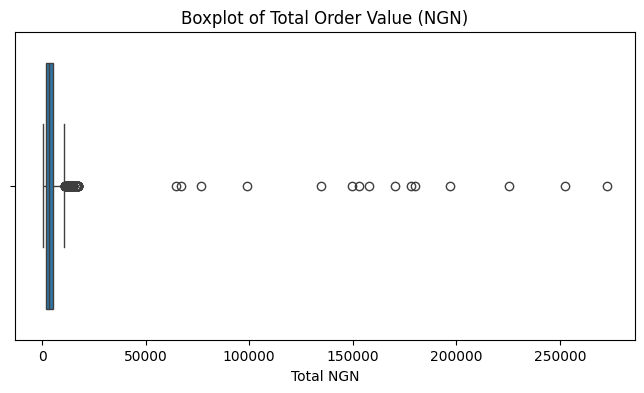

In [40]:
# 2. Draw a boxplot of Total_NGN.
plt.figure(figsize=(8, 4))
sns.boxplot(x=clean_df['Total_NGN'])
plt.title('Boxplot of Total Order Value (NGN)')
plt.xlabel('Total NGN')
plt.show()

In [41]:
# 3. Create a new column called Month from Date.
clean_df['Month'] = clean_df['Date'].dt.strftime('%B')
print(clean_df[['Date', 'Month']].head())

        Date      Month
0 2025-08-03     August
1 2025-03-14      March
2 2025-11-11   November
3 2025-03-09      March
4 2025-09-07  September


In [42]:
# 4. Change Is_Delivery from Yes and No into 1 and 0.
clean_df['Is_Delivery'] = clean_df['Is_Delivery'].map({'Yes': 1, 'No': 0})
print(clean_df['Is_Delivery'].value_counts())

Is_Delivery
0    3555
1    1395
Name: count, dtype: int64


# Week 6 Classwork: Exploratory Data Analysis

This section covers descriptive stats, correlations, visualization with Matplotlib/Seaborn, and deeper business insights.

## Monday: Summary Statistics, Correlation Analysis

In [43]:
# 1. Use describe() on Total_NGN
print(clean_df['Total_NGN'].describe())

# 2. Find the average Total_NGN for each Branch
avg_sales_branch = clean_df.groupby('Branch')['Total_NGN'].mean()
print("\n--- Avg Sales per Branch ---")
display(avg_sales_branch.to_frame())

# 3. Find the correlation between Quantity and Total_NGN
corr_qty_total = clean_df['Quantity'].corr(clean_df['Total_NGN'])
print(f"\nCorrelation between Quantity and Total_NGN: {corr_qty_total:.4f}")

count      4950.000000
mean       4541.141414
std        9572.949583
min         500.000000
25%        1800.000000
50%        3300.000000
75%        5400.000000
max      272500.000000
Name: Total_NGN, dtype: float64

--- Avg Sales per Branch ---


,Total_NGN
Branch,
Abuja Wuse,4819.673123
Enugu Ogui,3963.080685
Ibadan Bodija,4207.449210
Jos Terminus,4362.094763
Kaduna Central,4097.458704
Kano Sabon Gari,4246.656761
Lagos Yaba,5702.312775
Port Harcourt GRA,3982.504970



Correlation between Quantity and Total_NGN: 0.9724


In [44]:
# 4. Print mean and median of Total_NGN. Which one is bigger?
mean_val = clean_df['Total_NGN'].mean()
median_val = clean_df['Total_NGN'].median()
print(f"Mean: {mean_val:.2f}")
print(f"Median: {median_val:.2f}")
print("Mean is bigger." if mean_val > median_val else "Median is bigger (or equal).")

# 5. Count how many orders each Item has
print("\n--- Order Count per Item ---")
display(clean_df['Item'].value_counts().to_frame())

# 6. Find the total Total_NGN for each Payment_Method
print("\n--- Total Revenue by Payment Method ---")
display(clean_df.groupby('Payment_Method')['Total_NGN'].sum().to_frame())

Mean: 4541.14
Median: 3300.00
Mean is bigger.

--- Order Count per Item ---


,count
Item,
Beef Suya,1495
Chicken Suya,1142
Kilishi,708
Ram Suya,627
Gizzard,599
Soft Drink,379



--- Total Revenue by Payment Method ---


,Total_NGN
Payment_Method,
Cash,8507300
POS,5758600
Transfer,7497850
Unknown,714900


In [45]:
# 7. Find the average Rating for each Branch
print("--- Average Rating per Branch ---")
display(clean_df.groupby('Branch')['Rating'].mean().to_frame())

# 8. Find the correlation between Customer_Age and Total_NGN
corr_age_total = clean_df['Customer_Age'].corr(clean_df['Total_NGN'])
print(f"\nCorrelation (Customer_Age vs Total_NGN): {corr_age_total:.4f}")

# 9. Find the correlation between Quantity and Rating
corr_qty_rating = clean_df['Quantity'].corr(clean_df['Rating'])
print(f"Correlation (Quantity vs Rating): {corr_qty_rating:.4f}")

# 10. Find percentage of delivery vs non-delivery orders
delivery_pct = clean_df['Is_Delivery'].value_counts(normalize=True) * 100
print("\n--- Delivery Percentages (1=Yes, 0=No) ---")
display(delivery_pct.to_frame('Percentage'))

--- Average Rating per Branch ---


,Rating
Branch,
Abuja Wuse,4.065160
Enugu Ogui,4.055703
Ibadan Bodija,4.081340
Jos Terminus,4.059140
Kaduna Central,3.976323
Kano Sabon Gari,4.035200
Lagos Yaba,4.055156
Port Harcourt GRA,4.017316



Correlation (Customer_Age vs Total_NGN): -0.0236
Correlation (Quantity vs Rating): -0.0146

--- Delivery Percentages (1=Yes, 0=No) ---


,Percentage
Is_Delivery,
0,71.818182
1,28.181818


## Wednesday: Matplotlib, Seaborn, Business Insights

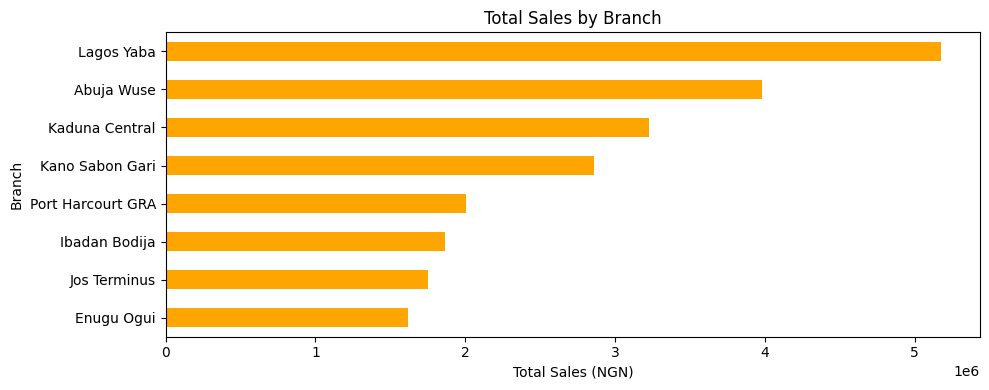

In [46]:
# 1. Bar chart of total sales for each Branch
plt.figure(figsize=(10, 4))
sales_by_branch = clean_df.groupby('Branch')['Total_NGN'].sum().sort_values()
sales_by_branch.plot(kind='barh', color='orange')
plt.title('Total Sales by Branch')
plt.xlabel('Total Sales (NGN)')
plt.tight_layout()
plt.show()

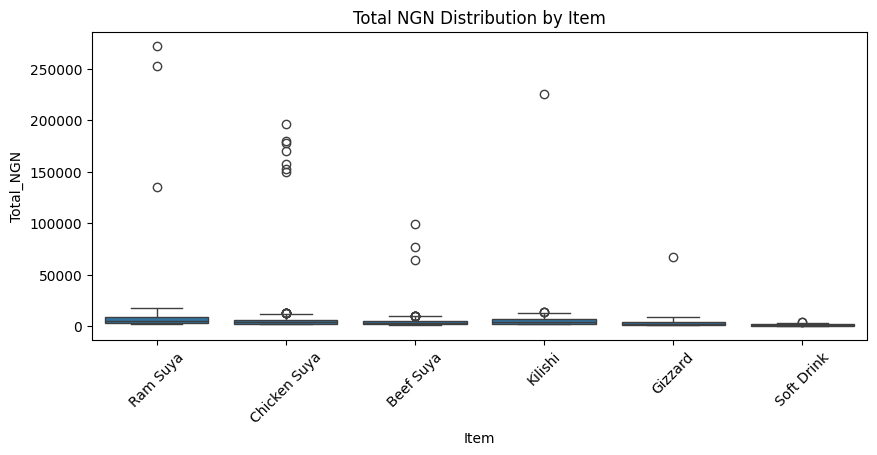

In [47]:
# 2. Seaborn boxplot of Total_NGN for each Item
plt.figure(figsize=(10, 4))
sns.boxplot(data=clean_df, x='Item', y='Total_NGN')
plt.title('Total NGN Distribution by Item')
plt.xticks(rotation=45)
plt.show()

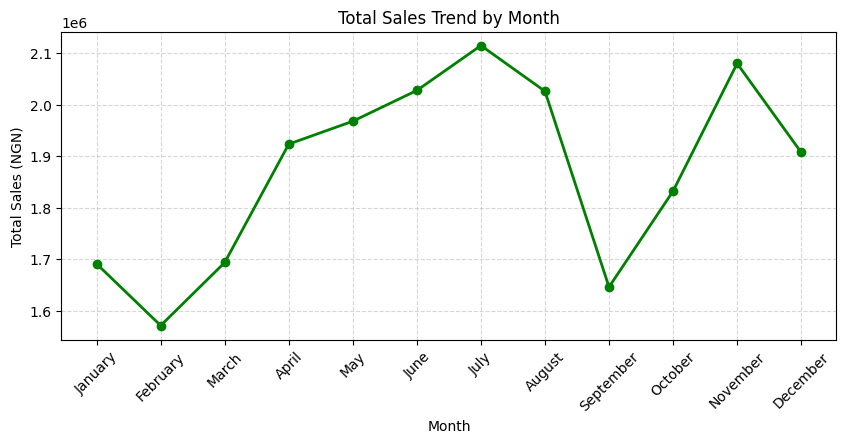

In [48]:
# Helper ordering for Months
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly_rev = clean_df.groupby('Month')['Total_NGN'].sum().reindex(month_order).dropna()

# 3. Line chart of total sales for each Month
plt.figure(figsize=(10, 4))
plt.plot(monthly_rev.index, monthly_rev.values, marker='o', color='green', linewidth=2)
plt.title('Total Sales Trend by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales (NGN)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

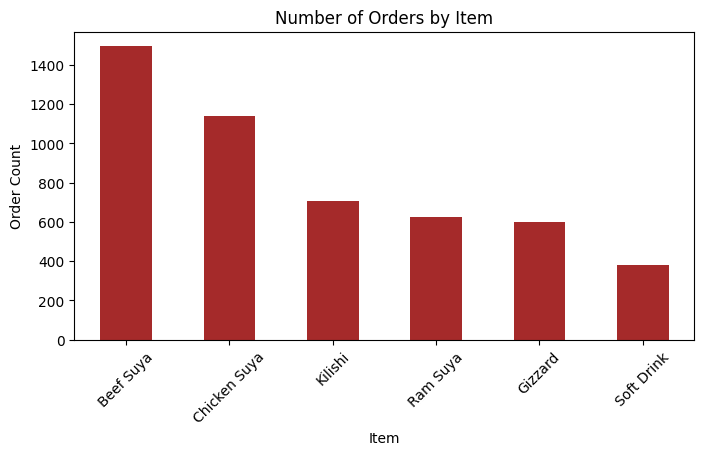

In [49]:
# 4. Bar chart of the number of orders for each Item
plt.figure(figsize=(8, 4))
clean_df['Item'].value_counts().plot(kind='bar', color='brown')
plt.title('Number of Orders by Item')
plt.ylabel('Order Count')
plt.xticks(rotation=45)
plt.show()

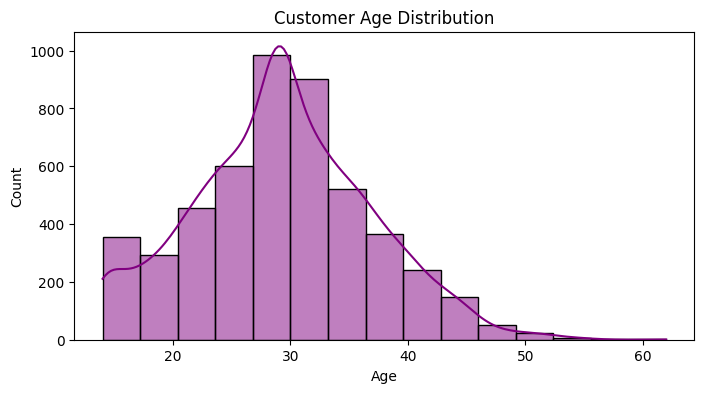

In [50]:
# 5. Histogram of Customer_Age
plt.figure(figsize=(8, 4))
sns.histplot(clean_df['Customer_Age'], bins=15, kde=True, color='purple')
plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.show()

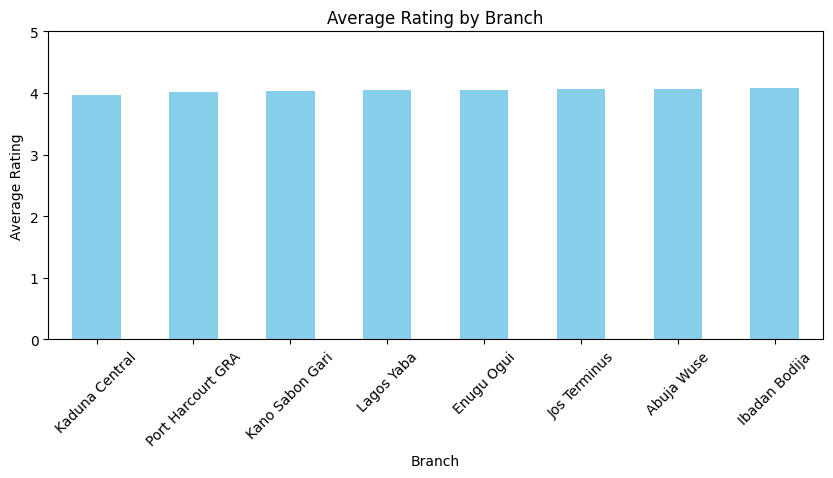

In [51]:
# 6. Bar chart of the average Rating for each Branch
plt.figure(figsize=(10, 4))
clean_df.groupby('Branch')['Rating'].mean().sort_values().plot(kind='bar', color='skyblue')
plt.title('Average Rating by Branch')
plt.ylabel('Average Rating')
plt.ylim(0, 5)
plt.xticks(rotation=45)
plt.show()

/tmp/ipykernel_460/461001694.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clean_df, x='Payment_Method', palette='Set2')


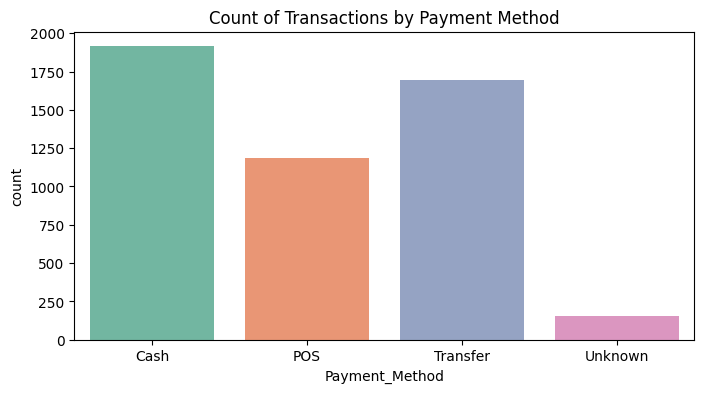

In [52]:
# 7. Seaborn countplot of Payment_Method
plt.figure(figsize=(8, 4))
sns.countplot(data=clean_df, x='Payment_Method', palette='Set2')
plt.title('Count of Transactions by Payment Method')
plt.show()

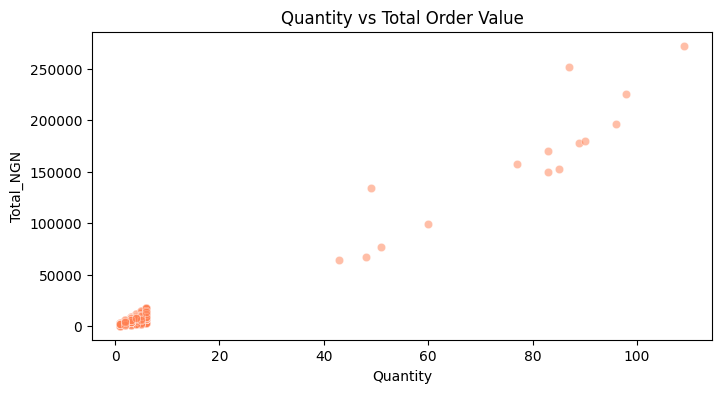

In [53]:
# 8. Scatter plot of Quantity against Total_NGN
plt.figure(figsize=(8, 4))
sns.scatterplot(data=clean_df, x='Quantity', y='Total_NGN', alpha=0.5, color='coral')
plt.title('Quantity vs Total Order Value')
plt.show()

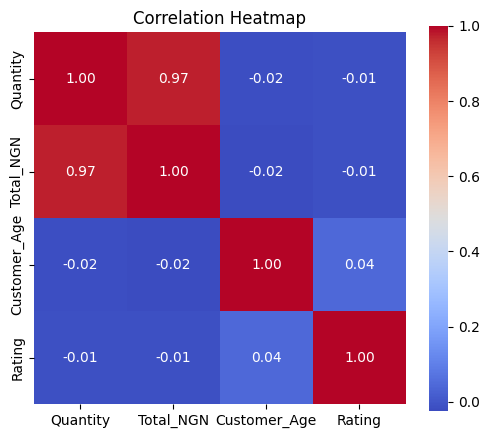

In [54]:
# 9. Correlation heatmap of Quantity, Total_NGN, Customer_Age and Rating
plt.figure(figsize=(6, 5))
corr_matrix = clean_df[['Quantity', 'Total_NGN', 'Customer_Age', 'Rating']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Correlation Heatmap')
plt.show()

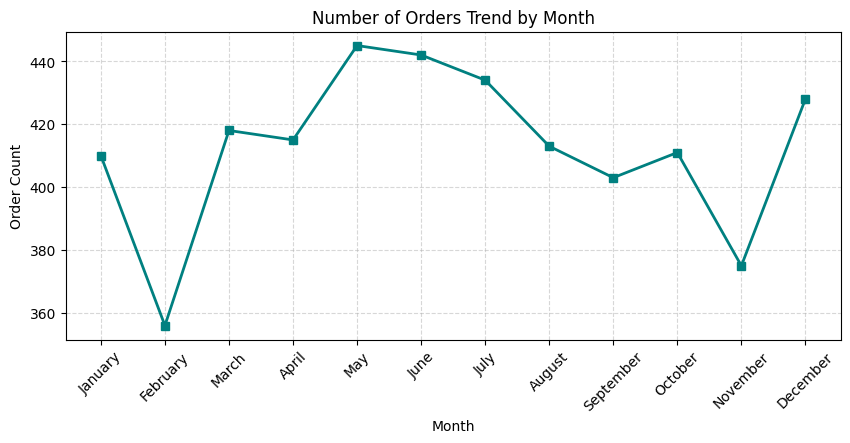

In [55]:
# 10. Line chart of the number of orders for each Month
monthly_orders = clean_df.groupby('Month')['Order_ID'].count().reindex(month_order).dropna()
plt.figure(figsize=(10, 4))
plt.plot(monthly_orders.index, monthly_orders.values, marker='s', color='teal', linewidth=2)
plt.title('Number of Orders Trend by Month')
plt.xlabel('Month')
plt.ylabel('Order Count')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Digging Deeper: Business Insights

In [56]:
# 1. Find the total sales for each Item inside each Branch
branch_item_sales = clean_df.groupby(['Branch', 'Item'])['Total_NGN'].sum().reset_index()
best_pair = branch_item_sales.sort_values(by='Total_NGN', ascending=False).iloc[0]
print(f"Best performing Pair: {best_pair['Branch']} - {best_pair['Item']} with {best_pair['Total_NGN']} NGN\n")

# 2. Find average Total_NGN for delivery orders and other orders
avg_delivery_spend = clean_df.groupby('Is_Delivery')['Total_NGN'].mean()
print("Average Spend by Delivery (1=Yes, 0=No):")
print(avg_delivery_spend.to_string())

# 3. Which Payment_Method has the highest average Total_NGN?
avg_payment_spend = clean_df.groupby('Payment_Method')['Total_NGN'].mean().sort_values(ascending=False)
print("\nAverage Spend by Payment Method:")
print(avg_payment_spend.to_string())

Best performing Pair: Lagos Yaba - Chicken Suya with 1635900 NGN

Average Spend by Delivery (1=Yes, 0=No):
Is_Delivery
0    4483.094233
1    4689.068100

Average Spend by Payment Method:
Payment_Method
POS         4851.390059
Unknown     4703.289474
Cash        4442.454308
Transfer    4420.902123


In [57]:
# 4. Count how many orders have a Rating of 5 and how many have a Rating of 1
rating_counts = clean_df['Rating'].value_counts()
print(f"Number of 5-star ratings: {rating_counts.get(5.0, 0)}")
print(f"Number of 1-star ratings: {rating_counts.get(1.0, 0)}\n")

# 5. Find the average Rating for each Item
avg_item_ratings = clean_df.groupby('Item')['Rating'].mean().sort_values(ascending=False)
print("Average Rating per Item:")
print(avg_item_ratings.to_string())

Number of 5-star ratings: 1401
Number of 1-star ratings: 0

Average Rating per Item:
Item
Chicken Suya    4.075598
Ram Suya        4.069324
Soft Drink      4.045198
Beef Suya       4.027007
Gizzard         4.018182
Kilishi         4.004532


# Week 9 Classwork: Statistics

This section reviews foundational statistics concepts including descriptive statistics (mean, median, mode), variance/standard deviation, probability, sampling, distributions, and calculating a 95% confidence interval.

## Monday: Descriptive Statistics, Probability

In [58]:
# 1. Find the mean, median and mode of Total_NGN
mean_total = clean_df['Total_NGN'].mean()
median_total = clean_df['Total_NGN'].median()
mode_total = clean_df['Total_NGN'].mode()[0]

print(f"Mean of Total_NGN: {mean_total:.2f} NGN")
print(f"Median of Total_NGN: {median_total:.2f} NGN")
print(f"Mode of Total_NGN: {mode_total:.2f} NGN")

Mean of Total_NGN: 4541.14 NGN
Median of Total_NGN: 3300.00 NGN
Mode of Total_NGN: 1500.00 NGN


In [59]:
# 2. Find the standard deviation of Customer_Age
std_age = clean_df['Customer_Age'].std()
print(f"Standard Deviation of Customer_Age: {std_age:.4f} years")

Standard Deviation of Customer_Age: 7.5925 years


In [60]:
# 3. Find the probability that a random order is a delivery
# Since Is_Delivery was mapped to 1 (Yes) and 0 (No), the mean represents this probability
prob_delivery = clean_df['Is_Delivery'].mean()
print(f"Probability that a random order is a delivery: {prob_delivery:.4f} ({prob_delivery * 100:.2f}%%)")

Probability that a random order is a delivery: 0.2818 (28.18%%)


## Wednesday: Sampling, Distributions, Confidence Intervals

In [61]:
# 1. Take a random sample of 100 orders. Compare its average Total_NGN to the average of all orders.
np.random.seed(42)  # Setting a seed for reproducible results
sample_100 = clean_df.sample(n=100)

sample_mean = sample_100['Total_NGN'].mean()
population_mean = clean_df['Total_NGN'].mean()

print(f"Average Total_NGN of 100 Sampled Orders: {sample_mean:.2f} NGN")
print(f"Average Total_NGN of All 5,000 Orders:     {population_mean:.2f} NGN")
print(f"Difference: {abs(sample_mean - population_mean):.2f} NGN")

Average Total_NGN of 100 Sampled Orders: 4491.00 NGN
Average Total_NGN of All 5,000 Orders:     4541.14 NGN
Difference: 50.14 NGN


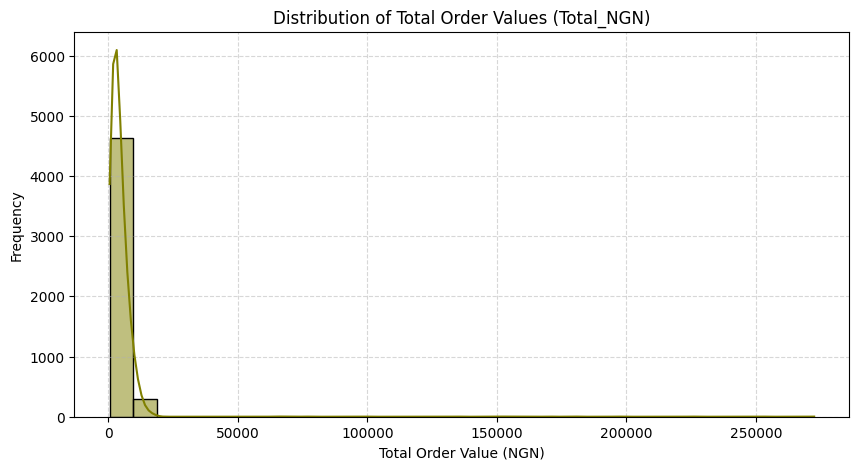

In [62]:
# 2. Draw a histogram of Total_NGN
plt.figure(figsize=(10, 5))
sns.histplot(clean_df['Total_NGN'], bins=30, kde=True, color='olive')
plt.title('Distribution of Total Order Values (Total_NGN)')
plt.xlabel('Total Order Value (NGN)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [63]:
# 3. Find a 95%% confidence interval for the average Total_NGN using a sample of 200 orders.
# Hint: average ± 1.96 × (standard deviation / √200)
sample_200 = clean_df.sample(n=200, random_state=42)
x_bar = sample_200['Total_NGN'].mean()
s = sample_200['Total_NGN'].std()
n = 200

margin_of_error = 1.96 * (s / np.sqrt(n))
lower_bound = x_bar - margin_of_error
upper_bound = x_bar + margin_of_error

print(f"Sample Mean (x̄): {x_bar:.2f} NGN")
print(f"Sample Standard Deviation (s): {s:.2f} NGN")
print(f"Margin of Error: {margin_of_error:.2f} NGN")
print(f"95%% Confidence Interval: [{lower_bound:.2f} NGN, {upper_bound:.2f} NGN]")

Sample Mean (x̄): 4406.00 NGN
Sample Standard Deviation (s): 2952.50 NGN
Margin of Error: 409.20 NGN
95%% Confidence Interval: [3996.80 NGN, 4815.20 NGN]
